In [ ]:
!pip install google-generativeai pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.6 MB/s eta 0:00:00
  Attempting uninstall: sqlalchemy
    Found existing installation: SQLAlchemy 2.0.43
    Uninstalling SQLAlchemy-2.0.43:
      Successfully uninstalled SQLAlchemy-2.0.43
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython-sql 0.5.0 requires sqlalchemy>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.
google-adk 1.14.1 requires sqlalchemy<3.0.0,>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.


In [ ]:
import google.generativeai as genai
import os
import pandas as pd
from google.colab import userdata
from helpers.utils import processar_lotes, plot_confusion

os.environ['GOOGLE_API_KEY'] = userdata.get('GOOGLE_API_KEY')
genai.configure(api_key=os.environ['GOOGLE_API_KEY'])

In [ ]:
#Definindo o modelo
model = genai.GenerativeModel("gemini-2.5-flash")

In [ ]:
#carregar base de dados
df = pd.read_csv("/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv")
df['label'].value_counts(normalize=True)

,proportion
label,
0,0.7
1,0.3


## Carregar os prompts


In [ ]:
zero_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/zero_shot/zero_shot.txt", "r").read()
one_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/one_shot/one_shot.txt", "r").read()
few_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/few_shot/few_shot.txt", "r").read()

## Aplicar a classificação com cada prompt


In [ ]:
# Processar lotes
df_final = processar_lotes(df, model, zero_shot_prompt, 'pred_zero_shot', batch_size=5)

classificação com: pred_zero_shot


In [ ]:
# Processar lotes
df_final = processar_lotes(df, model, one_shot_prompt, 'pred_one_shot', batch_size=5)

classificação com: pred_one_shot


In [ ]:
# Processar lotes
df_final = processar_lotes(df, model, few_shot_prompt, 'pred_few_shot', batch_size=5)

classificação com: pred_few_shot


## Avaliação das técnicas de prompt

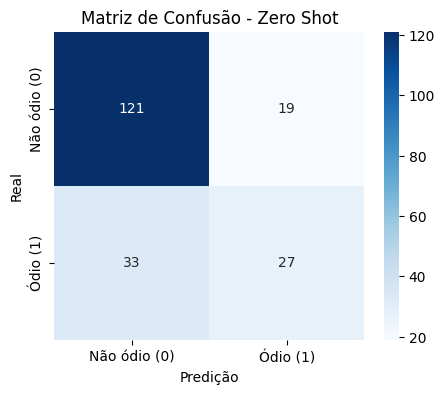


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.79      0.86      0.82       140
           1       0.59      0.45      0.51        60

    accuracy                           0.74       200
   macro avg       0.69      0.66      0.67       200
weighted avg       0.73      0.74      0.73       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/gemini/report_zero_shot.txt'
plot_confusion(df_final["label"], df_final["pred_zero_shot"].astype(int), "Matriz de Confusão - Zero Shot", path)

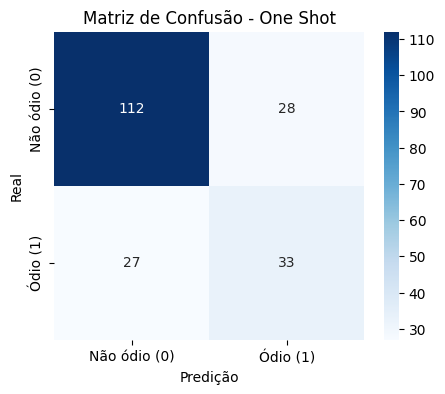


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.81      0.80      0.80       140
           1       0.54      0.55      0.55        60

    accuracy                           0.72       200
   macro avg       0.67      0.68      0.67       200
weighted avg       0.73      0.72      0.73       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/gemini/report_one_shot.txt'
plot_confusion(df_final["label"], df_final["pred_one_shot"].astype(int), "Matriz de Confusão - One Shot", path)

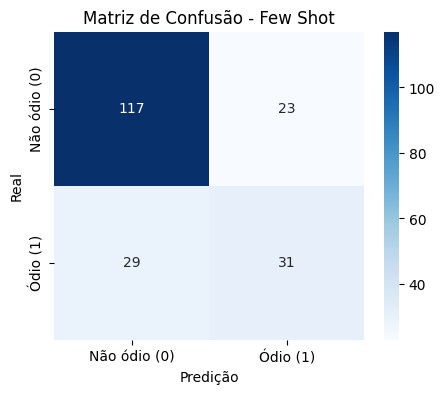


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       140
           1       0.57      0.52      0.54        60

    accuracy                           0.74       200
   macro avg       0.69      0.68      0.68       200
weighted avg       0.73      0.74      0.74       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/gemini/report_few_shot.txt'
plot_confusion(df_final["label"], df_final["pred_few_shot"].astype(int), "Matriz de Confusão - Few Shot", path)